Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Imbalance Handling

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

Load Dataset

In [3]:
df = pd.read_csv("../data/raw/creditcard.csv")
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Basic Information

In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Data Understanding and Quality Checks

In [5]:

# 1. Dataset dimensions
print("Dataset shape:", df.shape)

# 2. Column names
print("\nColumns:")
print(df.columns.tolist())

# 3. Data types and non-null counts
print("\nDataset information:")
df.info()

# 4. Missing values
print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 6. Target class distribution
print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())

print("\nClass percentage:")
print(
    (df["Class"].value_counts(normalize=True).sort_index() * 100)
    .round(4)
)


Dataset shape: (284807, 31)

Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     2848

Investigate Data quality

In [6]:

# Check missing values
total_missing = df.isnull().sum().sum()
print("Total missing values:", total_missing)

# Show columns with missing values, if any
print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate rows
duplicate_count = df.duplicated().sum()
print("\nDuplicate rows:", duplicate_count)

# Count each target class
print("\nClass counts:")
print(df["Class"].value_counts().sort_index())

# Calculate fraud percentage
fraud_percentage = df["Class"].mean() * 100
print(f"\nFraud percentage: {fraud_percentage:.4f}%")

# Calculate class imbalance ratio
class_counts = df["Class"].value_counts()
imbalance_ratio = class_counts[0] / class_counts[1]

print(f"Legitimate-to-fraud ratio: {imbalance_ratio:.2f}:1")


Total missing values: 0

Columns with missing values:
Series([], dtype: int64)

Duplicate rows: 1081

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%
Legitimate-to-fraud ratio: 577.88:1


EDA

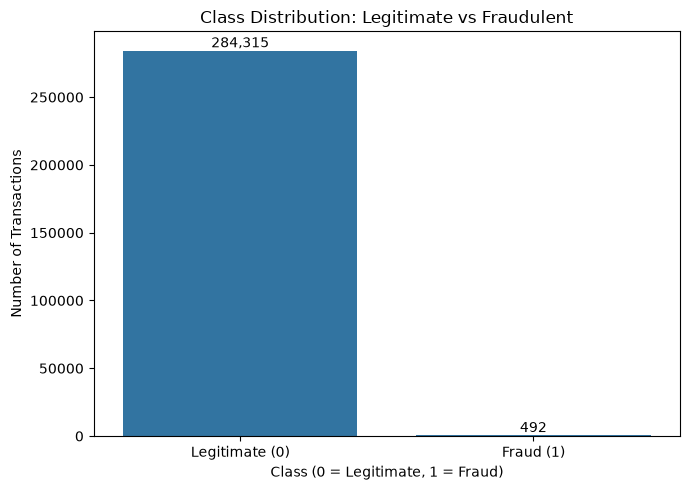

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count each class
class_counts = df["Class"].value_counts().sort_index()

# Plot class distribution
plt.figure(figsize=(7, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Class Distribution: Legitimate vs Fraudulent")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])

# Display count above each bar
for i, count in enumerate(class_counts.values):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


Transaction amount Distribution

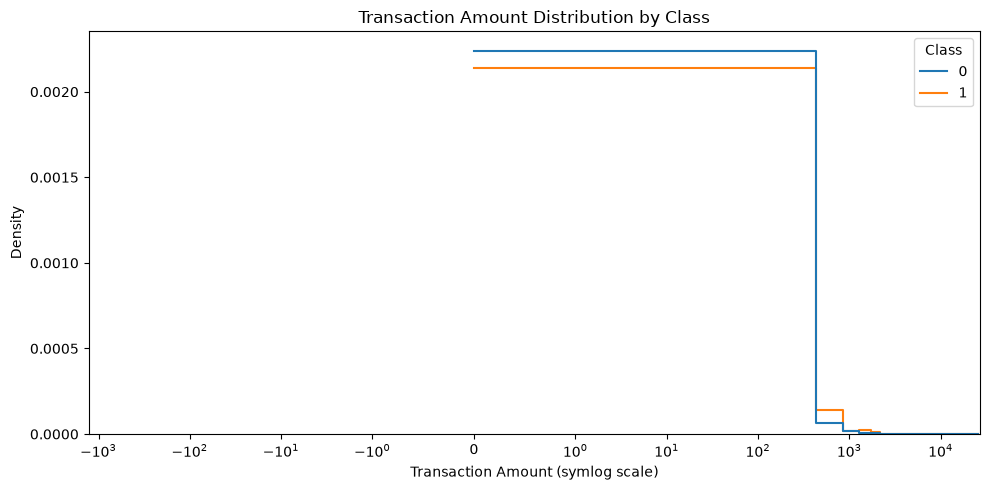

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.xscale("symlog", linthresh=1)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount (symlog scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


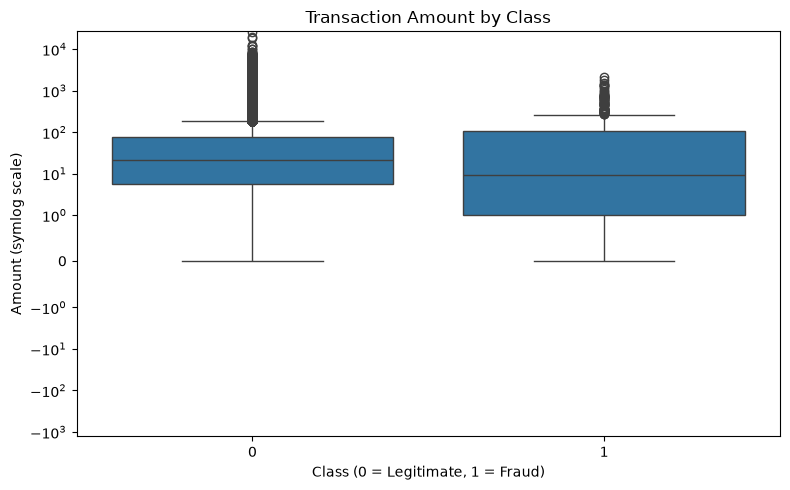

In [9]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.yscale("symlog", linthresh=1)
plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Amount (symlog scale)")
plt.tight_layout()
plt.show()


Summary Statistics

In [10]:

amount_summary = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(amount_summary.round(2))


        count    mean  median     std  min       max
Class                                               
0      284315   88.29   22.00  250.11  0.0  25691.16
1         492  122.21    9.25  256.68  0.0   2125.87


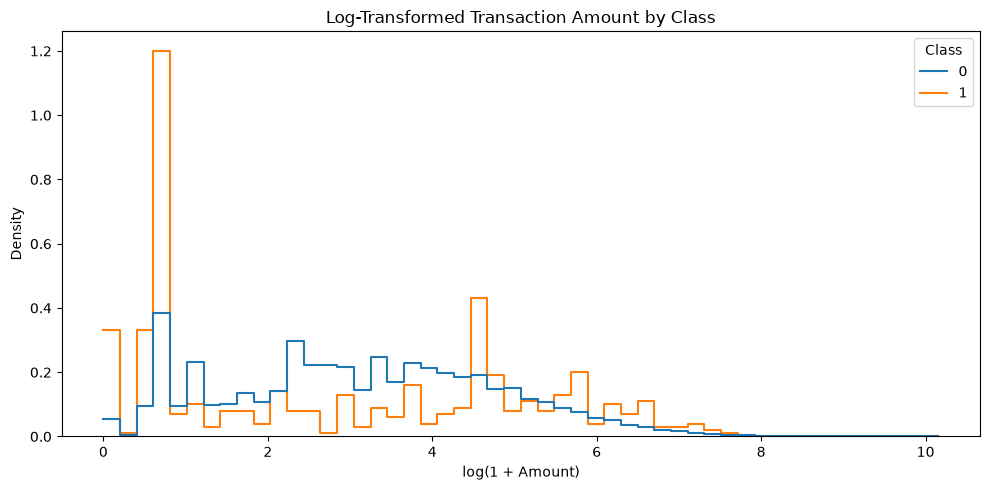

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Log-transform the amount for visualization only
plot_df = df[["Amount", "Class"]].copy()
plot_df["LogAmount"] = np.log1p(plot_df["Amount"])

plt.figure(figsize=(10, 5))

sns.histplot(
    data=plot_df,
    x="LogAmount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Log-Transformed Transaction Amount by Class")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


Time Feature

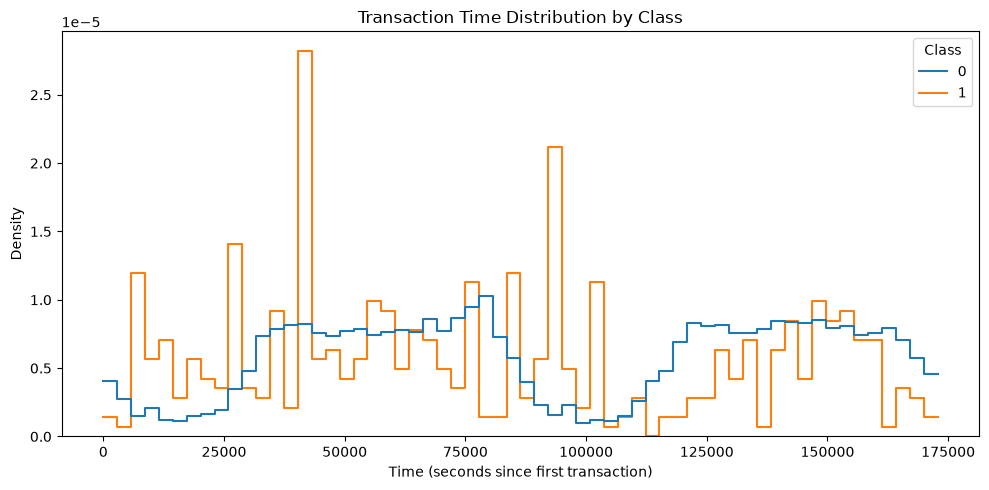

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (seconds since first transaction)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [14]:

time_summary = df.groupby("Class")["Time"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(time_summary.round(2))


        count      mean   median       std    min       max
Class                                                      
0      284315  94838.20  84711.0  47484.02    0.0  172792.0
1         492  80746.81  75568.5  47835.37  406.0  170348.0


Fraud vs Non-Fraud Distribution

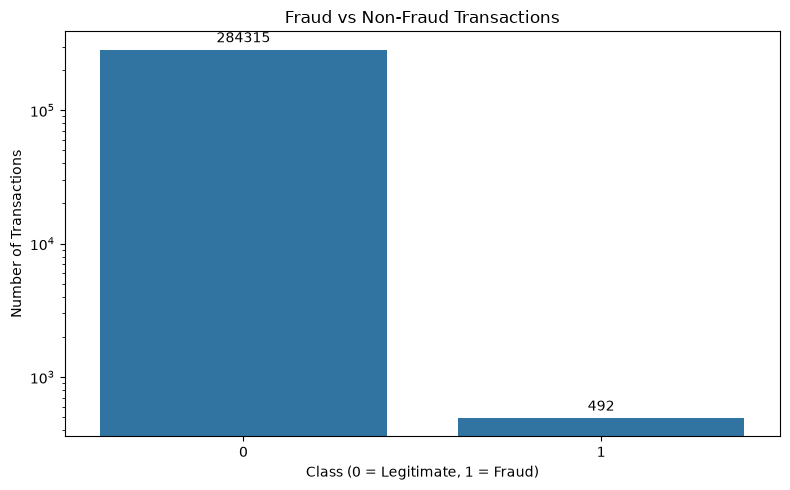

Fraud percentage: 0.1727 %


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Class"
)

ax.set_title("Fraud vs Non-Fraud Transactions")
ax.set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
ax.set_ylabel("Number of Transactions")
ax.set_yscale("log")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

print("Fraud percentage:",
      round(df["Class"].mean() * 100, 4), "%")

Correlation Heatmap

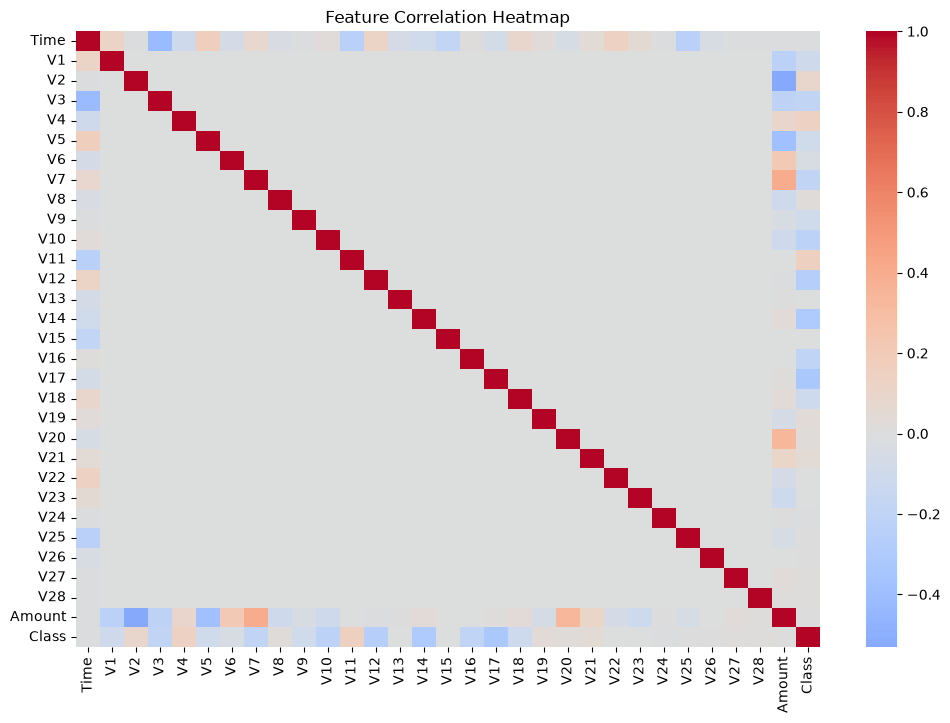

In [8]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

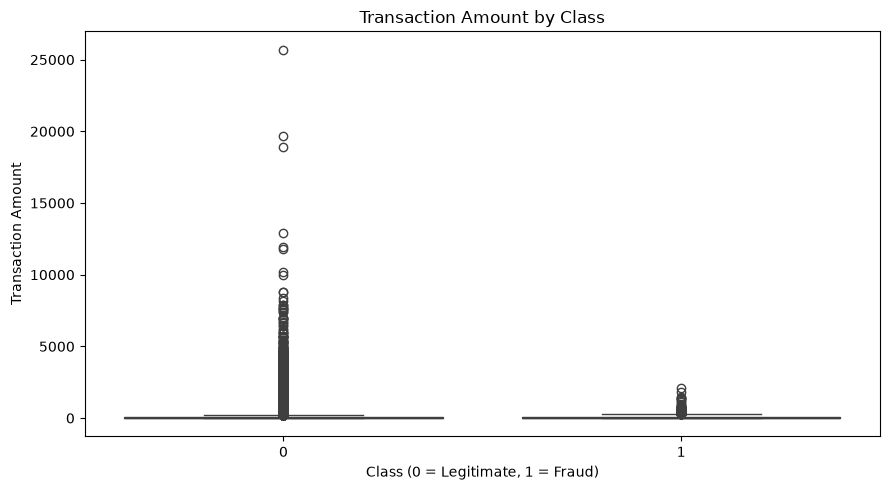

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [9]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe())

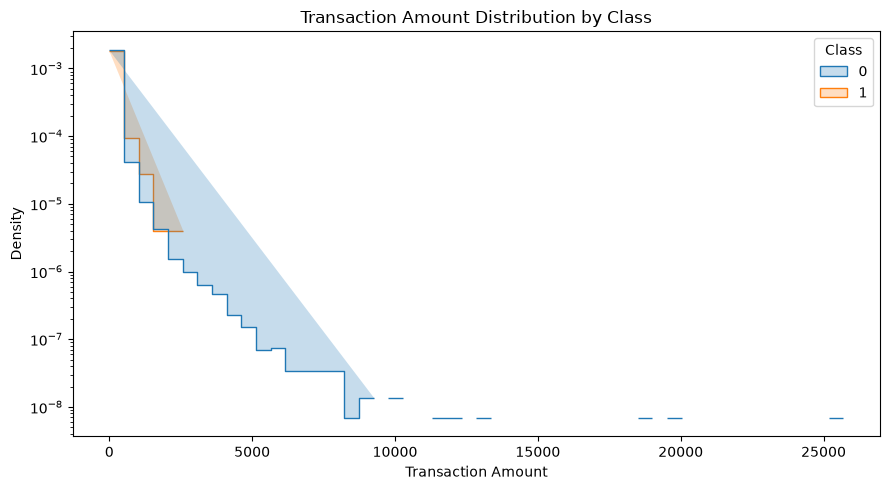

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

Distibution of PCA

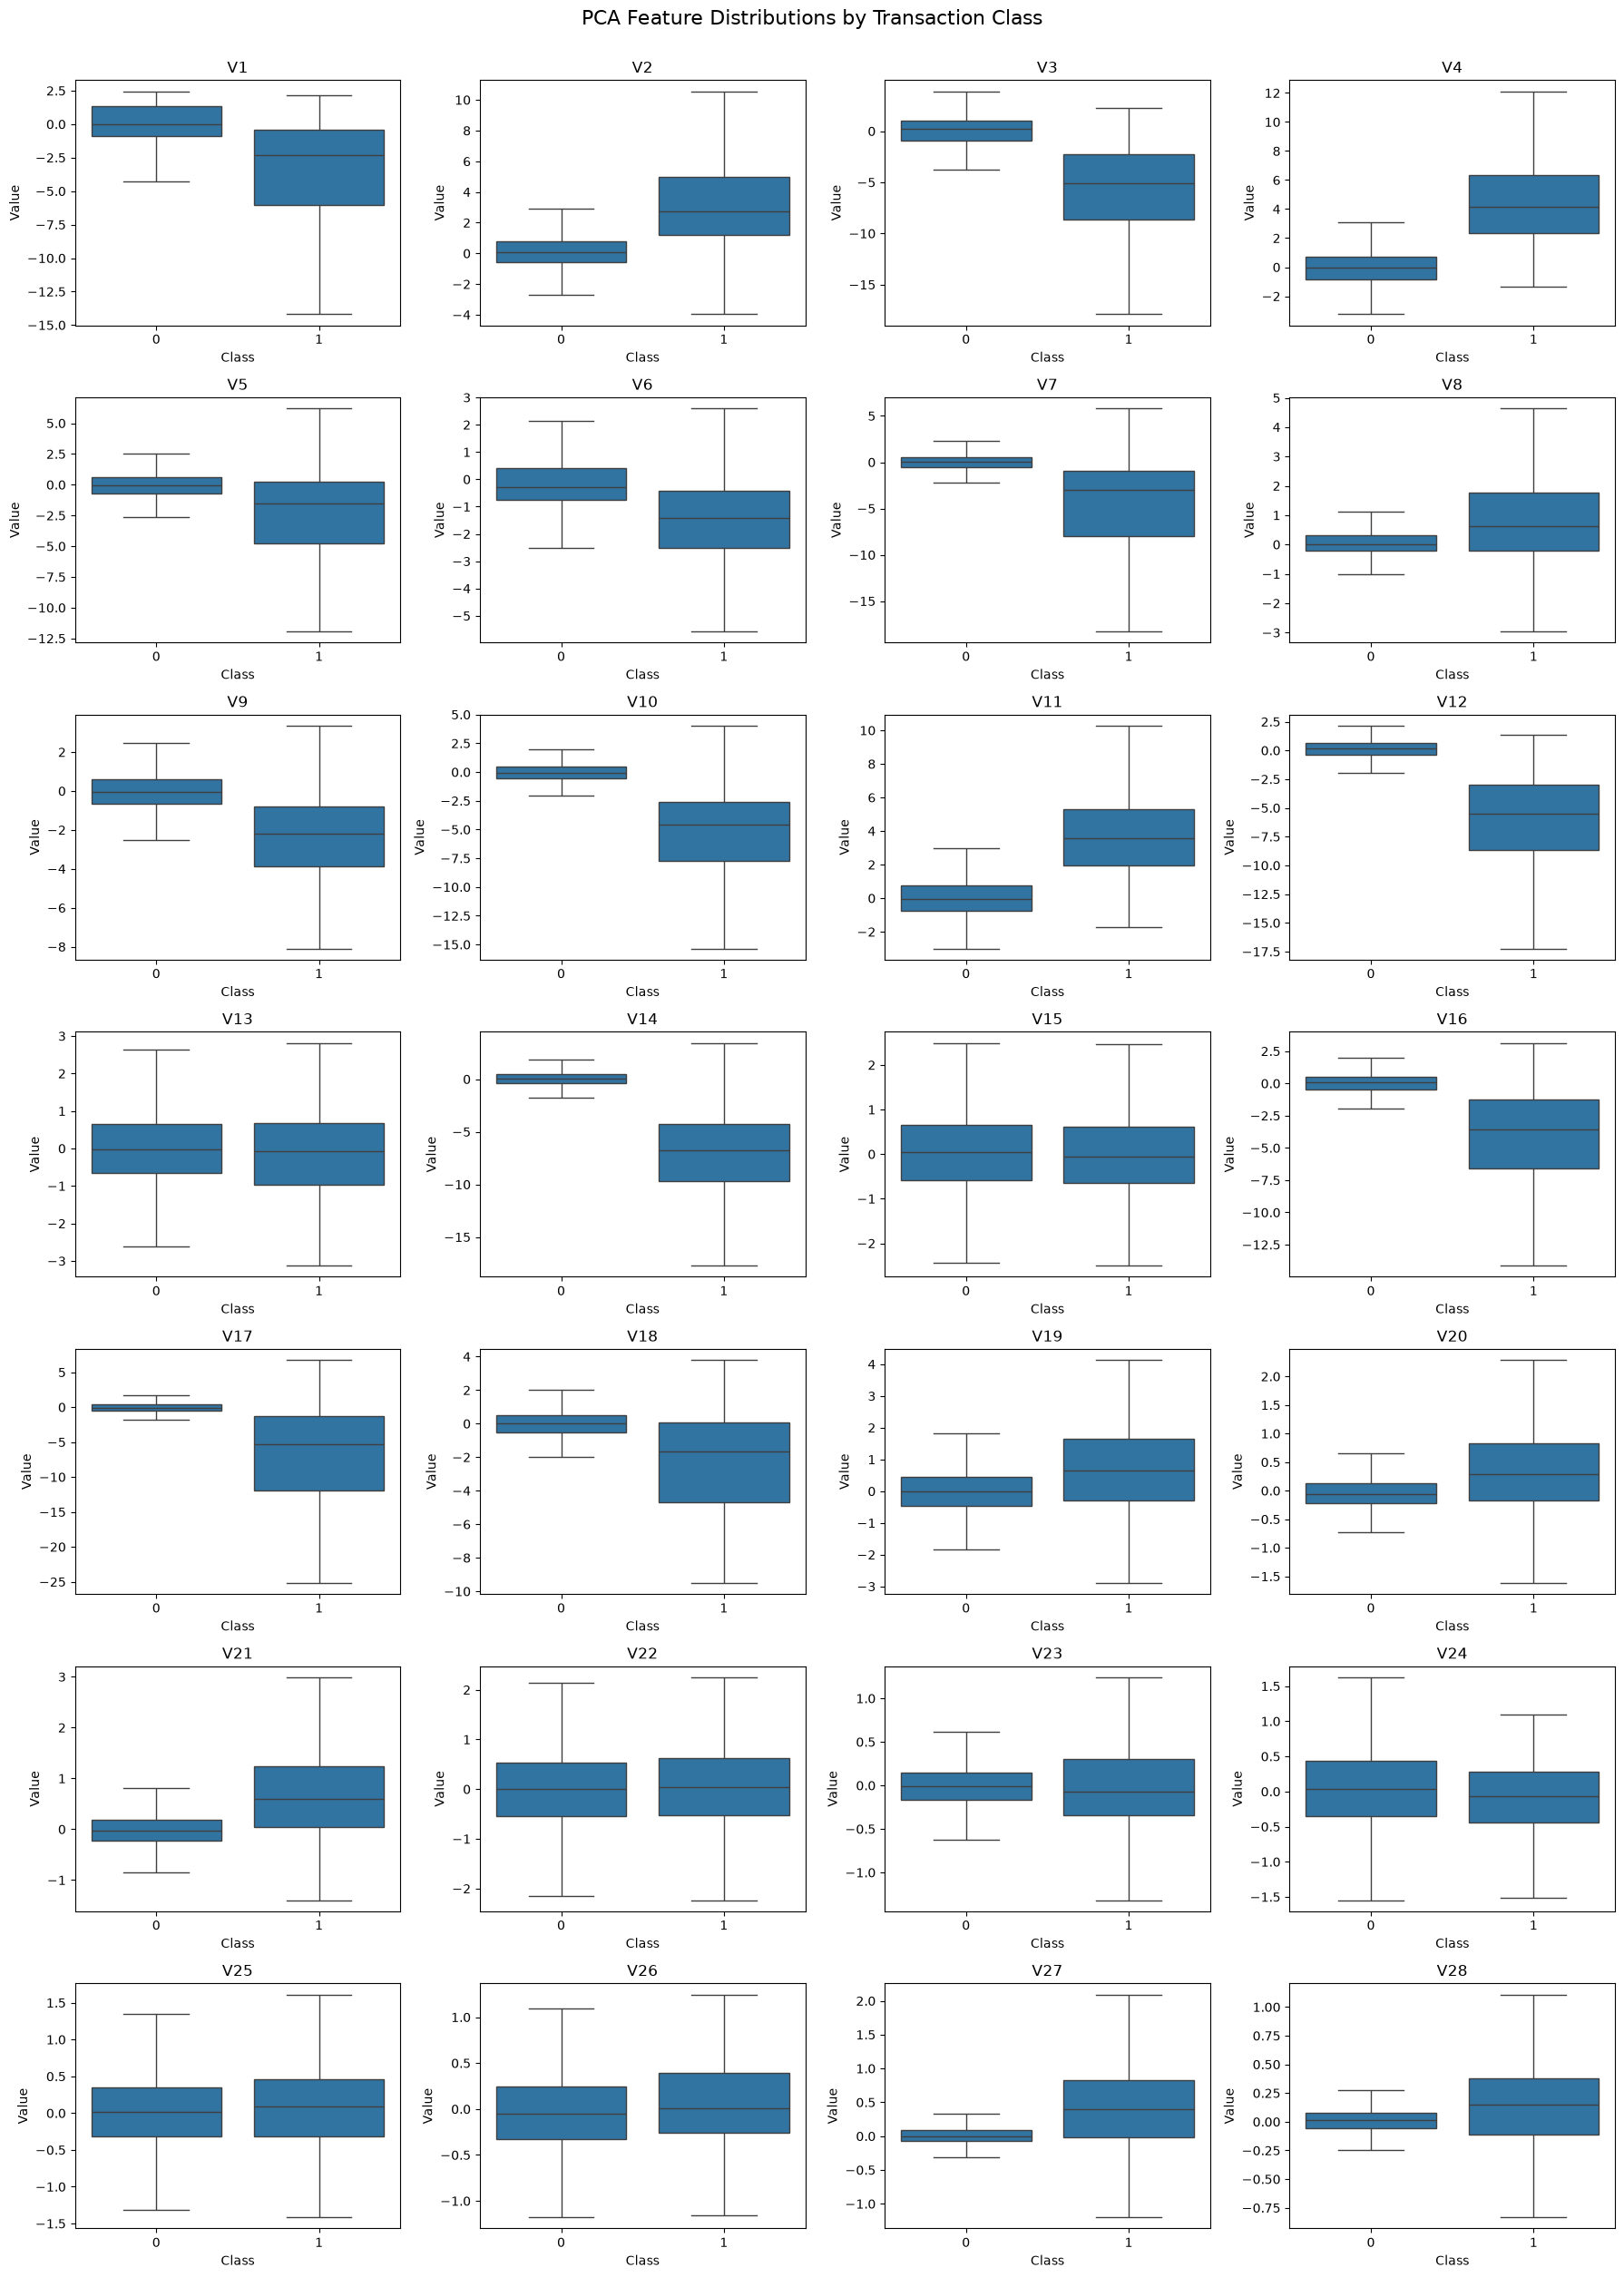

In [16]:

# Select PCA features
pca_features = [f"V{i}" for i in range(1, 29)]

# Plot the distributions of all PCA features
fig, axes = plt.subplots(7, 4, figsize=(18, 25))
axes = axes.flatten()

for i, feature in enumerate(pca_features):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        ax=axes[i],
        showfliers=False
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel("Value")

plt.suptitle(
    "PCA Feature Distributions by Transaction Class",
    fontsize=16,
    y=1.002
)
plt.tight_layout()
plt.show()


Features with the largest absolute mean differences:
V3    -7.0455
V14   -6.9838
V17   -6.6774
V12   -6.2702
V10   -5.6867
V7    -5.5784
V1    -4.7802
V4     4.5499
V16   -4.1471
V11    3.8067
dtype: float64


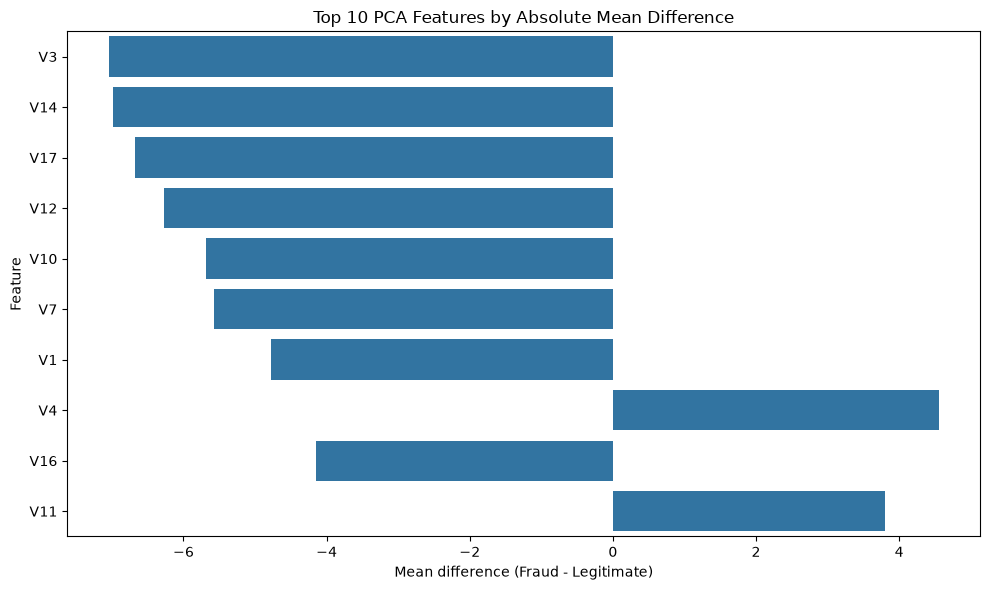

In [17]:

# Compare feature means between classes
fraud_means = df.groupby("Class")[pca_features].mean()

mean_difference = (
    fraud_means.loc[1] - fraud_means.loc[0]
).sort_values(key=abs, ascending=False)

print("Features with the largest absolute mean differences:")
print(mean_difference.head(10).round(4))

# Visualize the top 10
plt.figure(figsize=(10, 6))

sns.barplot(
    x=mean_difference.head(10).values,
    y=mean_difference.head(10).index
)

plt.title("Top 10 PCA Features by Absolute Mean Difference")
plt.xlabel("Mean difference (Fraud - Legitimate)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Features most correlated with Class:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V11    0.1549
V4     0.1334
V18   -0.1115
V1    -0.1013
V9    -0.0977
V5    -0.0950
V2     0.0913
V6    -0.0436
Name: Class, dtype: float64


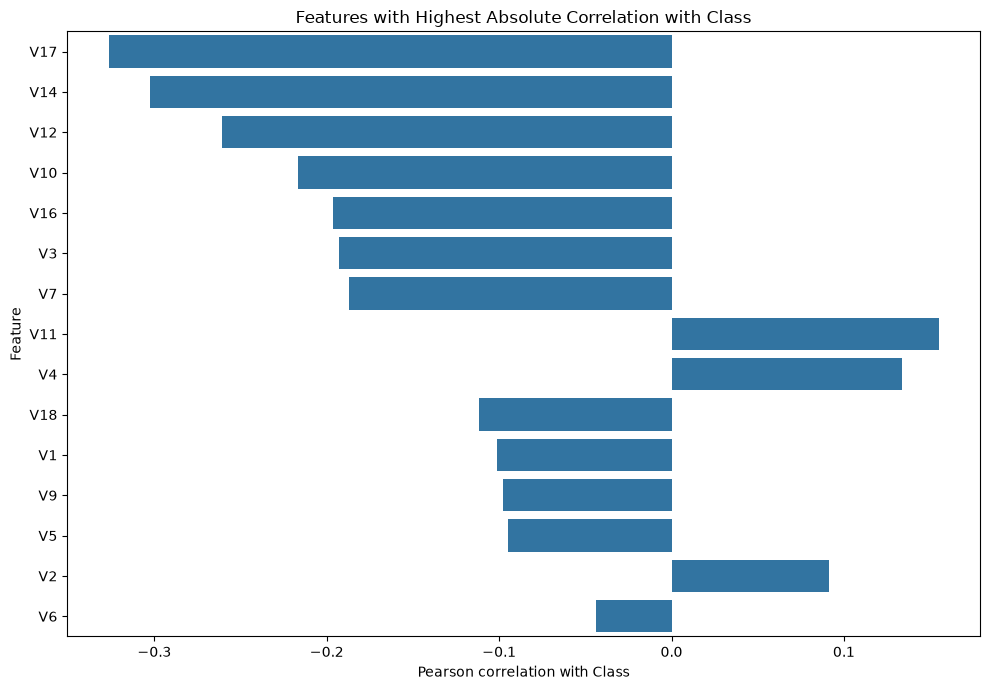

In [18]:
correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

print("Features most correlated with Class:")
print(correlations.head(15).round(4))

plt.figure(figsize=(10, 7))

sns.barplot(
    x=correlations.head(15).values,
    y=correlations.head(15).index
)

plt.title("Features with Highest Absolute Correlation with Class")
plt.xlabel("Pearson correlation with Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Data Preparation

In [20]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Class"])
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (284807, 30)
Target shape: (284807,)

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [21]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in testing set:", int(y_test.sum()))

print("\nTraining fraud percentage:",
      round(y_train.mean() * 100, 4), "%")

print("Testing fraud percentage:",
      round(y_test.mean() * 100, 4), "%")


Training features: (227845, 30)
Testing features: (56962, 30)

Fraud cases in training set: 394
Fraud cases in testing set: 98

Training fraud percentage: 0.1729 %
Testing fraud percentage: 0.172 %


Baseline Logistic Regression

In [22]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build a leakage-safe pipeline
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train on the training data
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully.")


Baseline Logistic Regression trained successfully.


In [23]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Predictions
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

# Classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Additional metrics
print("\nAverage Precision (PR-AUC summary):",
      round(average_precision_score(y_test, y_proba), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_proba), 4))


Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9994    0.9998    0.9996     56864
       Fraud     0.8267    0.6327    0.7168        98

    accuracy                         0.9991     56962
   macro avg     0.9130    0.8162    0.8582     56962
weighted avg     0.9991    0.9991    0.9991     56962

Confusion Matrix:
[[56851    13]
 [   36    62]]

Average Precision (PR-AUC summary): 0.7414
ROC-AUC: 0.9605


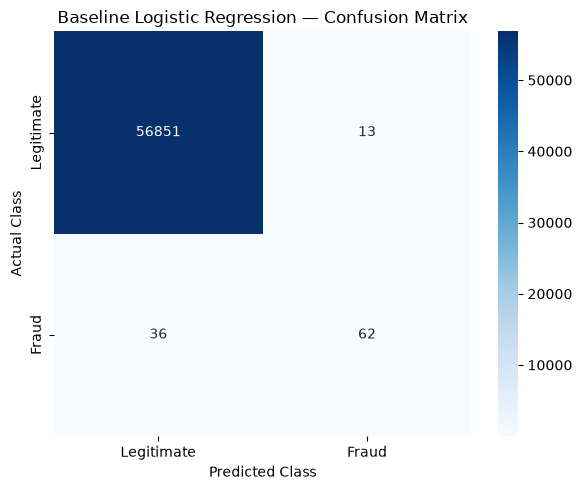

In [24]:

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


Handling Imbalance

In [25]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

weighted_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

weighted_model.fit(X_train, y_train)

weighted_pred = weighted_model.predict(X_test)
weighted_proba = weighted_model.predict_proba(X_test)[:, 1]

print("Weighted Logistic Regression")
print("Precision:", precision_score(y_test, weighted_pred, zero_division=0))
print("Recall:", recall_score(y_test, weighted_pred, zero_division=0))
print("F1-score:", f1_score(y_test, weighted_pred, zero_division=0))
print("Average Precision:", average_precision_score(y_test, weighted_proba))
print("ROC-AUC:", roc_auc_score(y_test, weighted_proba))


Weighted Logistic Regression
Precision: 0.06097560975609756
Recall: 0.9183673469387755
F1-score: 0.11435832274459974
Average Precision: 0.7189705771419241
ROC-AUC: 0.9720834996210077


In [26]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

smote_model.fit(X_train, y_train)

smote_pred = smote_model.predict(X_test)
smote_proba = smote_model.predict_proba(X_test)[:, 1]

print("SMOTE Logistic Regression")
print("Precision:", precision_score(y_test, smote_pred, zero_division=0))
print("Recall:", recall_score(y_test, smote_pred, zero_division=0))
print("F1-score:", f1_score(y_test, smote_pred, zero_division=0))
print("Average Precision:", average_precision_score(y_test, smote_proba))
print("ROC-AUC:", roc_auc_score(y_test, smote_proba))


SMOTE Logistic Regression
Precision: 0.057803468208092484
Recall: 0.9183673469387755
F1-score: 0.10876132930513595
Average Precision: 0.724469435669471
ROC-AUC: 0.9708434302252134


In [27]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

results = []

models = {
    "Baseline": (baseline_model, y_pred, y_proba),
    "Class Weighted": (weighted_model, weighted_pred, weighted_proba),
    "SMOTE": (smote_model, smote_pred, smote_proba)
}

for name, (model, pred, proba) in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Average Precision": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(4))


                Precision  Recall  F1-score  Average Precision  ROC-AUC
Model                                                                  
Baseline           0.8267  0.6327    0.7168             0.7414   0.9605
Class Weighted     0.0610  0.9184    0.1144             0.7190   0.9721
SMOTE              0.0578  0.9184    0.1088             0.7245   0.9708


In [28]:

from sklearn.model_selection import train_test_split

# Split the original training set into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training set:", X_train_sub.shape)
print("Validation set:", X_val.shape)
print("Fraud cases in validation set:", int(y_val.sum()))


Model training set: (182276, 30)
Validation set: (45569, 30)
Fraud cases in validation set: 79


In [29]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

threshold_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

threshold_model.fit(X_train_sub, y_train_sub)

# Get probabilities on validation data
val_proba = threshold_model.predict_proba(X_val)[:, 1]

print("Validation model trained successfully.")


Validation model trained successfully.


In [30]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:
    val_pred = (val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "Flagged transactions": int(val_pred.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))


 Threshold  Precision  Recall  F1-score  Flagged transactions
       0.1     0.0096  0.9494    0.0191                  7787
       0.2     0.0183  0.9114    0.0358                  3943
       0.3     0.0297  0.9114    0.0575                  2426
       0.4     0.0421  0.8861    0.0804                  1662
       0.5     0.0599  0.8861    0.1123                  1168
       0.6     0.0828  0.8734    0.1513                   833
       0.7     0.1147  0.8608    0.2024                   593
       0.8     0.1502  0.8481    0.2552                   446


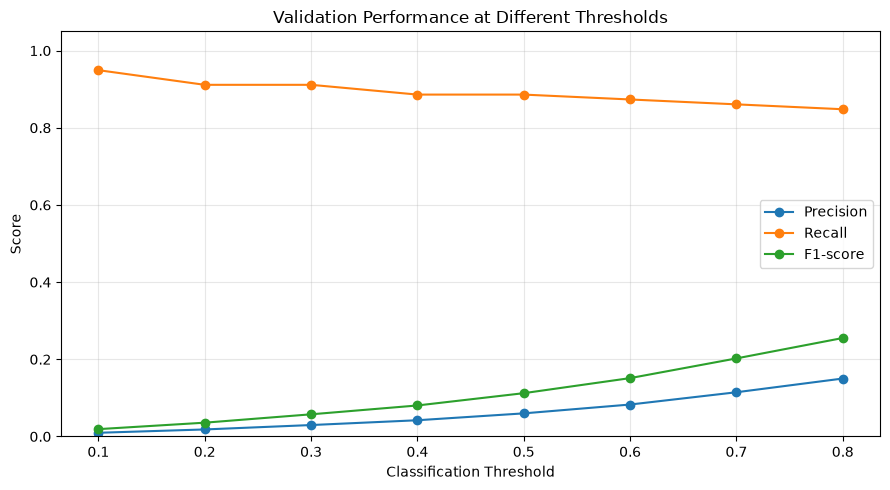

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Validation Performance at Different Thresholds")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [32]:

# Select the threshold with the highest validation F1-score
best_row = threshold_df.loc[threshold_df["F1-score"].idxmax()]

best_threshold = float(best_row["Threshold"])

print("Selected threshold:", best_threshold)
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-score"], 4))
print(
    "Validation transactions flagged:",
    int(best_row["Flagged transactions"])
)


Selected threshold: 0.8
Validation precision: 0.1502
Validation recall: 0.8481
Validation F1-score: 0.2552
Validation transactions flagged: 446


In [33]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

print("Final model trained on the full training set.")


Final model trained on the full training set.


Selected threshold: 0.8

Final Test Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9998    0.9919    0.9959     56864
       Fraud     0.1596    0.8878    0.2706        98

    accuracy                         0.9918     56962
   macro avg     0.5797    0.9399    0.6332     56962
weighted avg     0.9984    0.9918    0.9946     56962

Average Precision: 0.719
ROC-AUC: 0.9721


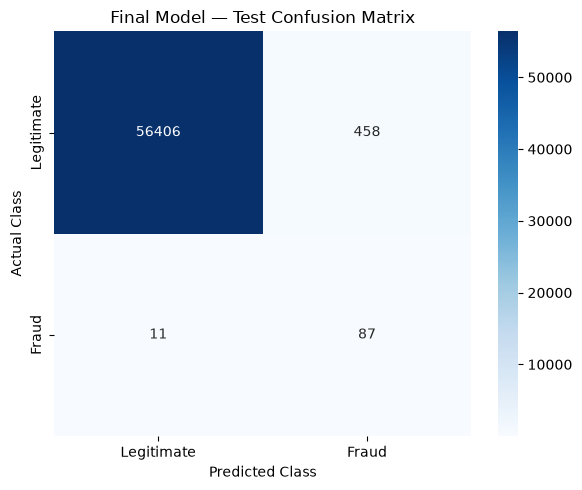

In [34]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict probabilities on the untouched test set
test_proba = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
test_pred = (test_proba >= best_threshold).astype(int)

print("Selected threshold:", best_threshold)

print("\nFinal Test Classification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4,
    zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test, test_proba), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_proba), 4))

cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Final Model — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [37]:

# Select one transaction for testing
sample = df.drop(columns=["Class"]).iloc[0]

print(sample.to_string())
print("\nActual class:", int(df["Class"].iloc[0]))


Time        0.000000
V1         -1.359807
V2         -0.072781
V3          2.536347
V4          1.378155
V5         -0.338321
V6          0.462388
V7          0.239599
V8          0.098698
V9          0.363787
V10         0.090794
V11        -0.551600
V12        -0.617801
V13        -0.991390
V14        -0.311169
V15         1.468177
V16        -0.470401
V17         0.207971
V18         0.025791
V19         0.403993
V20         0.251412
V21        -0.018307
V22         0.277838
V23        -0.110474
V24         0.066928
V25         0.128539
V26        -0.189115
V27         0.133558
V28        -0.021053
Amount    149.620000

Actual class: 0


In [38]:

from pathlib import Path

# Create a sample CSV containing 100 transactions
sample_path = Path("data") / "sample_transactions.csv"

sample_path.parent.mkdir(parents=True, exist_ok=True)

df.drop(columns=["Class"]).head(100).to_csv(
    sample_path,
    index=False,
)

print("Sample CSV created at:", sample_path.resolve())


Sample CSV created at: D:\My_Projects\fraud_detection\notebooks\data\sample_transactions.csv


In [36]:
from pathlib import Path
import joblib

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": final_model,
        "threshold": best_threshold,
        "features": list(X_train.columns)
    },
    models_dir / "fraud_detection_model.joblib"
)

['models\\fraud_detection_model.joblib']